# S03: Thesis pair discovery on intraday bars

Pre-registration: [`003_claude_s03_thesis_pair_discovery_intraday.md`](../../discussions/Pairs_Cointegration/003_claude_s03_thesis_pair_discovery_intraday.md).
1. The thesis pipeline (`igarpet/Thesis` 01–02), unchanged except for bar size.
2. Johansen, rolling cointegration, and economic-distance clustering (GICS, correlation clusters).
3. A random-pair null, and out-of-sample persistence with frozen parameters.

Set `TIMEFRAME` below to `"30Min"` (primary) or `"15Min"`.

In [1]:
TIMEFRAME = "30Min"          # "30Min" (primary) or "15Min"
N_JOBS = -1                  # all CPU cores

import json, os, sys, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "equity_trading").exists())
sys.path.insert(0, str(ROOT / "src"))
from equity_trading import __version__
from equity_trading.alpaca import ALPACA_VERSION, download_years, regular_session_panel, synthetic_panel
from equity_trading.data import work_dir
from equity_trading.pairs import (PAIRS_VERSION, cluster_pairs, compute_returns, correlation_clusters, gics_pairs,
                                  integration_screen, mean_ci, oos_diagnostics, random_null_pairs,
                                  rolling_stability, screen_pairs, thesis_split, top_correlation_pairs)

SYNTHETIC = os.environ.get("S03_SYNTHETIC") == "1"
YEARS = list(range(2020, 2026))                      # 2026 sealed
CFG = dict(train_fraction=0.70, max_missing=0.05, top_n=10, coint_alpha=0.01, integration_alpha=0.05,
           johansen_max_lags=10, johansen_det_order=0, roll_window_sessions=63, roll_step_sessions=21,
           roll_alpha=0.05, roll_stable_share=0.5, max_cluster_size=40, n_null=3000, seed=42,
           entry_z=1.5, stop_z=3.0, intraday_ffill_bars=2)
BARS_PER_DAY = {"30Min": 13, "15Min": 26}[TIMEFRAME]

tag = ("synthetic_" if SYNTHETIC else "") + TIMEFRAME + f"_alpaca{ALPACA_VERSION}_pairs{PAIRS_VERSION}"  # cache is invalidated when data or test code changes
OUT = ROOT / "notebooks" / "Pairs_Cointegration" / ("03_synthetic" if SYNTHETIC else "03") / TIMEFRAME
OUT.mkdir(parents=True, exist_ok=True)
CACHE = work_dir() / "results" / "s03" / tag
CACHE.mkdir(parents=True, exist_ok=True)

COL = {"corr": "#2a78d6", "gics": "#eb6834", "cluster": "#1baf7a", "null": "#8a8a84"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e6e3", "grid.linewidth": 0.6, "axes.titleweight": "bold", "font.size": 9})

if SYNTHETIC:
    from equity_trading.universe import SECTOR_ETF_01, UNIVERSE_01
    constituents = pd.DataFrame([{"Symbol": s, "GICS Sector": k, "GICS Sub-Industry": k}
                                 for k, v in UNIVERSE_01.items() for s in v])
    YEARS, CFG["n_null"] = [2024, 2025], 150
else:
    constituents = pd.read_csv(ROOT / "src" / "equity_trading" / "reference" / "sp500_constituents_20260913.csv")
SYMBOLS = sorted(constituents["Symbol"].unique())
print(f"{TIMEFRAME} | synthetic={SYNTHETIC} | symbols={len(SYMBOLS)} | cache={CACHE}")

30Min | synthetic=False | symbols=503 | cache=D:\MarketData\EquityTrading\results\s03\30Min_alpaca0.3.0_pairs0.1.1


## 1. Data (thesis notebook 01)

In [2]:
t0 = time.time()
if SYNTHETIC:
    prices = synthetic_panel(UNIVERSE_01, SECTOR_ETF_01, YEARS, bars_per_day=BARS_PER_DAY, seed=3)[SYMBOLS]
else:
    download_years(SYMBOLS, TIMEFRAME, YEARS, workers=8)
    prices = regular_session_panel(SYMBOLS, TIMEFRAME, YEARS, ffill_limit=CFG["intraday_ffill_bars"])
print(f"panel {prices.shape} in {time.time() - t0:.0f}s; symbols with no Alpaca data: {sorted(set(SYMBOLS) - set(prices.columns))}")

_oos_miss = prices.iloc[int(len(prices) * CFG["train_fraction"]):].isna()
print(f"OOS bars missing after the {CFG['intraday_ffill_bars']}-bar fill: median per symbol {int(_oos_miss.sum().median())}, "
      f"symbols with any missing {int(_oos_miss.any().sum())} / {prices.shape[1]}")
print("missing OOS bars by bar start time (top 5):", _oos_miss.sum(axis=1).groupby(_oos_miss.index.time).sum().nlargest(5).to_dict())
train_prices, test_prices, availability = thesis_split(prices, CFG["train_fraction"], CFG["max_missing"])
availability.to_csv(OUT / "availability.csv", float_format="%.5f")
display(pd.DataFrame({"bars": [len(train_prices), len(test_prices)], "assets": [train_prices.shape[1], test_prices.shape[1]],
                      "start": [train_prices.index.min(), test_prices.index.min()],
                      "end": [train_prices.index.max(), test_prices.index.max()]}, index=["Formation", "Out of sample"]))
print("removed: formation missing > 5% or first price missing:", int((~(availability.formation_missing_fraction <= CFG["max_missing"]) | ~availability.first_price_valid).sum()),
      "| incomplete out of sample:", int((~availability.complete_out_of_sample).sum()))
train_log, test_log = np.log(train_prices), np.log(test_prices)
TICKERS = list(train_prices.columns)

30Min: 0 batches to download (0 symbol-years), 8 parallel requests
panel (19532, 501) in 70s; symbols with no Alpaca data: ['FDXF', 'HONA']
OOS bars missing after the 2-bar fill: median per symbol 0, symbols with any missing 10 / 501
missing OOS bars by bar start time (top 5): {datetime.time(12, 30): 1039, datetime.time(12, 0): 1030, datetime.time(11, 0): 1029, datetime.time(11, 30): 1029, datetime.time(9, 30): 1026}


,bars,assets,start,end
Formation,13672,473,2020-01-02 09:30:00-05:00,2024-03-12 12:00:00-04:00
Out of sample,5860,473,2024-03-12 12:30:00-04:00,2025-12-31 15:30:00-05:00


removed: formation missing > 5% or first price missing: 24 | incomplete out of sample: 10


## 2. Candidate pairs: thesis pre-screen, GICS, correlation clusters, null

In [3]:
corr = compute_returns(train_prices).corr()
cand = {"corr": top_correlation_pairs(corr, CFG["top_n"]),
        "gics": gics_pairs(TICKERS, constituents, "GICS Sub-Industry")}
n_sub = constituents.set_index("Symbol").loc[TICKERS, "GICS Sub-Industry"].nunique()
labels = correlation_clusters(corr, n_clusters=n_sub)
sizes = labels.value_counts()
cand["cluster"] = cluster_pairs(labels, CFG["max_cluster_size"])
union = set().union(*cand.values())
cand["null"] = random_null_pairs(TICKERS, union, CFG["n_null"], CFG["seed"])
labels.to_csv(OUT / "correlation_clusters.csv")
print(f"correlation clusters: {n_sub} (= GICS sub-industries) | largest {sizes.max()} | skipped (> {CFG['max_cluster_size']}): {int((sizes > CFG['max_cluster_size']).sum())}")
display(pd.DataFrame({k: [len(v)] for k, v in cand.items()}, index=["candidate pairs"]))
ov = pd.DataFrame({a: [len(set(cand[a]) & set(cand[b])) for b in ["corr", "gics", "cluster"]] for a in ["corr", "gics", "cluster"]},
                  index=["corr", "gics", "cluster"])
print("overlap between candidate sets (pairs):"); display(ov)

correlation clusters: 126 (= GICS sub-industries) | largest 96 | skipped (> 40): 1


,corr,gics,cluster,null
candidate pairs,3800,1272,1746,3000


overlap between candidate sets (pairs):


,corr,gics,cluster
corr,3800,829,1085
gics,829,1272,528
cluster,1085,528,1746


## 3. Integration screen, Engle–Granger (thesis) and Johansen

This is the slow step. Results are cached, so a re-run skips it.

In [4]:
roots_path, screen_path = CACHE / "roots.parquet", CACHE / "screen.parquet"
if roots_path.exists():
    roots = pd.read_parquet(roots_path)
else:
    t0 = time.time(); roots = integration_screen(train_log, TICKERS, CFG["integration_alpha"], n_jobs=N_JOBS)
    roots.to_parquet(roots_path); print(f"I(1) screen {time.time() - t0:.0f}s")
print(f"I(1) screen passed: {int(roots.i1.sum())} / {len(roots)}")

all_pairs = sorted(set().union(*cand.values()))
if screen_path.exists():
    screen = pd.read_parquet(screen_path)
    todo = sorted(set(all_pairs) - set(zip(screen.dependent, screen.independent)))
else:
    screen, todo = pd.DataFrame(), all_pairs
if todo:
    t0 = time.time()
    new = screen_pairs(train_log, todo, roots, CFG["coint_alpha"], johansen=True, johansen_max_lags=CFG["johansen_max_lags"],
                       johansen_det_order=CFG["johansen_det_order"], n_jobs=N_JOBS)
    screen = pd.concat([screen, new], ignore_index=True); screen.to_parquet(screen_path)
    print(f"tested {len(todo):,} pairs in {time.time() - t0:.0f}s")
screen = screen.set_index("pair")

I(1) screen 468s
I(1) screen passed: 443 / 473
tested 7,816 pairs in 7076s


## 4. Rolling (dynamic) cointegration inside the formation sample

In [5]:
roll_path = CACHE / "rolling.parquet"
W, S = CFG["roll_window_sessions"] * BARS_PER_DAY, CFG["roll_step_sessions"] * BARS_PER_DAY
if roll_path.exists():
    roll = pd.read_parquet(roll_path)
else:
    t0 = time.time()
    roll = rolling_stability(train_log, all_pairs, window=W, step=S, alpha=CFG["roll_alpha"], n_jobs=N_JOBS)
    roll.to_parquet(roll_path); print(f"rolling {time.time() - t0:.0f}s, {roll.roll_windows.iloc[0]} windows per pair")
screen = screen.join(roll.set_index("pair"))
screen["roll_stable"] = screen["roll_pass_share"] >= CFG["roll_stable_share"]
screen["egjo_selected"] = screen["eg_selected"] & screen["jo_selected"]
screen["egroll_selected"] = screen["eg_selected"] & screen["roll_stable"]
RULES = {"EG": "eg_selected", "JO": "jo_selected", "EG+JO": "egjo_selected", "EG+ROLL": "egroll_selected"}

rolling 253s, 48 windows per pair


## 5. Selection rates vs the null (G1)

In [6]:
def rows_of(name):
    return screen.loc[[f"{a}-{b}" for a, b in cand[name]]]

sel_rows = []
for name in ["corr", "gics", "cluster", "null"]:
    d = rows_of(name)
    r = {"set": name, "candidates": len(d), "i1_both": int(d.i1_screen.sum()), "eg_p<=1%": int((d.eg_p <= .01).sum())}
    for rule, col in RULES.items():
        r[rule] = int(d[col].sum()); r[rule + "_rate"] = d[col].mean()
    sel_rows.append(r)
sel = pd.DataFrame(sel_rows).set_index("set")
for rule in RULES:
    sel[rule + "_ratio_vs_null"] = sel[rule + "_rate"] / sel.loc["null", rule + "_rate"]
    sel[rule + "_est_false_share"] = (sel.loc["null", rule + "_rate"] * sel["candidates"] / sel[rule]).clip(upper=1)
sel.to_csv(OUT / "selection_rates.csv", float_format="%.5f")
display(sel.T.style.format(lambda v: f"{v:.4f}" if isinstance(v, float) else v))

set,corr,gics,cluster,null
candidates,3800.0000,1272.0000,1746.0000,3000.0000
i1_both,3430.0000,1085.0000,1363.0000,2636.0000
eg_p<=1%,135.0000,54.0000,69.0000,89.0000
EG,101.0000,27.0000,41.0000,43.0000
EG_rate,0.0266,0.0212,0.0235,0.0143
JO,122.0000,27.0000,47.0000,57.0000
JO_rate,0.0321,0.0212,0.0269,0.0190
EG+JO,64.0000,17.0000,21.0000,20.0000
EG+JO_rate,0.0168,0.0134,0.0120,0.0067
EG+ROLL,1.0000,1.0000,1.0000,0.0000


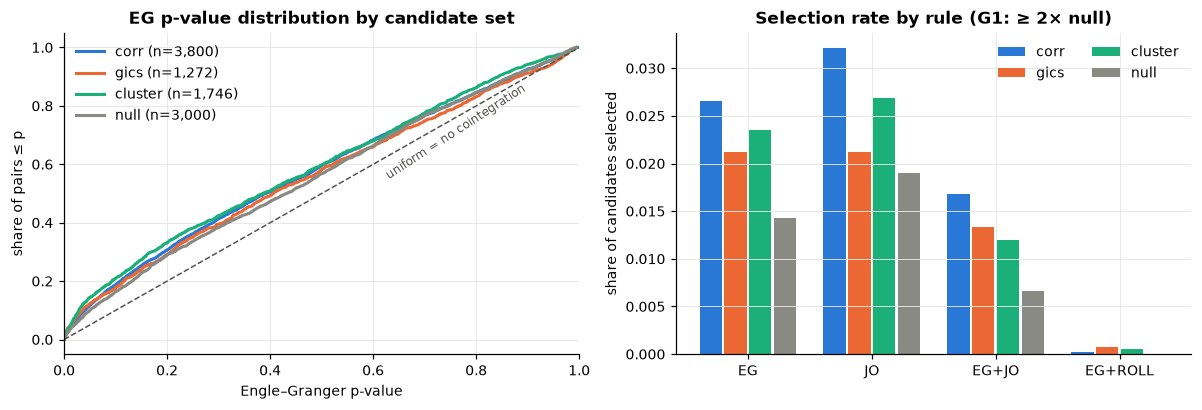

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
ax = axes[0]
for name in ["corr", "gics", "cluster", "null"]:
    p = np.sort(rows_of(name).eg_p.dropna().to_numpy())
    ax.plot(p, np.arange(1, len(p) + 1) / len(p), color=COL[name], lw=2, label=f"{name} (n={len(p):,})")
ax.plot([0, 1], [0, 1], color="#555550", ls="--", lw=1); ax.text(0.62, 0.55, "uniform = no cointegration", fontsize=8, color="#555550", rotation=33)
ax.set_xlim(0, 1); ax.set_xlabel("Engle–Granger p-value"); ax.set_ylabel("share of pairs ≤ p"); ax.legend(frameon=False)
ax.set_title("EG p-value distribution by candidate set")
ax = axes[1]
w = 0.2
for j, name in enumerate(["corr", "gics", "cluster", "null"]):
    ax.bar(np.arange(len(RULES)) + (j - 1.5) * w, [sel.loc[name, r + "_rate"] for r in RULES], w * 0.9, color=COL[name], label=name)
ax.set_xticks(range(len(RULES)), list(RULES)); ax.set_ylabel("share of candidates selected")
ax.set_title("Selection rate by rule (G1: ≥ 2× null)"); ax.legend(frameon=False, ncol=2)
fig.tight_layout(); plt.show()

Engle–Granger vs Johansen selections:


,EG only,JO only,both,neither
set,,,,
corr,37,58,64,3641
gics,10,10,17,1235
cluster,20,26,21,1679
null,23,37,20,2920


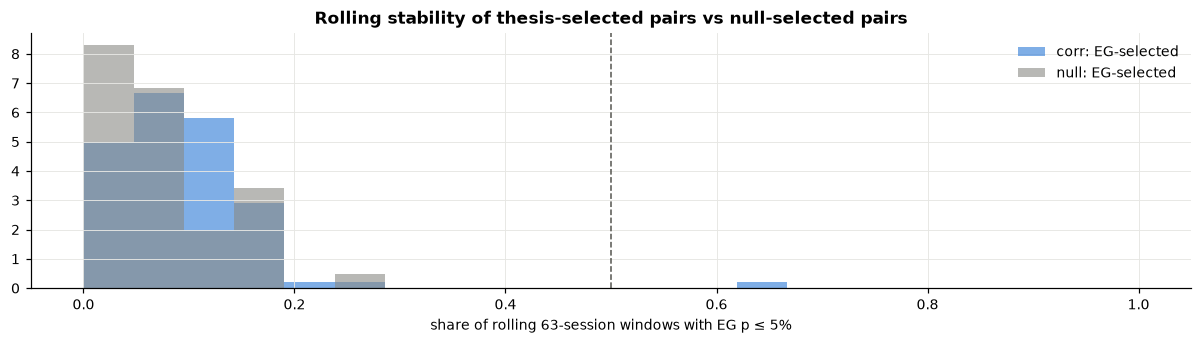

In [8]:
agree = []
for name in ["corr", "gics", "cluster", "null"]:
    d = rows_of(name)
    agree.append({"set": name, "EG only": int((d.eg_selected & ~d.jo_selected).sum()), "JO only": int((~d.eg_selected & d.jo_selected).sum()),
                  "both": int((d.eg_selected & d.jo_selected).sum()), "neither": int((~d.eg_selected & ~d.jo_selected).sum())})
agree = pd.DataFrame(agree).set_index("set"); agree.to_csv(OUT / "eg_johansen_agreement.csv")
print("Engle–Granger vs Johansen selections:"); display(agree)

fig, ax = plt.subplots(figsize=(11, 3.2))
bins = np.linspace(0, 1, 22)
for name in ["corr", "null"]:
    d = rows_of(name)
    if not d.eg_selected.any():
        continue
    ax.hist(d.loc[d.eg_selected, "roll_pass_share"], bins, density=True, alpha=0.6, color=COL[name], label=f"{name}: EG-selected")
ax.axvline(CFG["roll_stable_share"], color="#555550", ls="--", lw=1)
ax.set_xlabel(f"share of rolling {CFG['roll_window_sessions']}-session windows with EG p ≤ 5%"); ax.legend(frameon=False)
ax.set_title("Rolling stability of thesis-selected pairs vs null-selected pairs"); fig.tight_layout(); plt.show()

## 6. Out of sample with frozen formation parameters (G2)

In [9]:
G2_MIN, MIN_NULL_SELECTED = 0.10, 10
oos_rows, gates = {}, []
# fallback reference when a rule selects too few null pairs: all null pairs with their formation OLS fit
null_all = oos_diagnostics(train_log, test_log, rows_of("null").reset_index(), CFG["entry_z"], CFG["stop_z"])
for name in ["corr", "gics", "cluster", "null"]:
    d = rows_of(name).reset_index()
    for rule, col in RULES.items():
        s = d[d[col]]
        oos_rows[(name, rule)] = oos_diagnostics(train_log, test_log, s, CFG["entry_z"], CFG["stop_z"]) if len(s) else pd.DataFrame()
allo = pd.concat({f"{k[0]}|{k[1]}": v for k, v in oos_rows.items() if len(v)}, names=["set_rule"]).reset_index(level=0)
allo.to_csv(OUT / "oos_selected_pairs.csv", index=False, float_format="%.5f")

for name in ["corr", "gics", "cluster"]:
    for rule in RULES:
        a, b = oos_rows[(name, rule)], oos_rows[("null", rule)]
        ref = "null_selected_same_rule"
        if len(b) < MIN_NULL_SELECTED:
            b, ref = null_all, "all_null_pairs (too few null pairs selected)"
        g = {"set": name, "rule": rule, "selected": len(a), "null_selected": len(oos_rows[("null", rule)]), "null_reference": ref,
             "ratio_vs_null": sel.loc[name, rule + "_ratio_vs_null"]}
        for m in ["band_hold", "reversion_rate", "drift_sd"]:
            ma, la, ha = mean_ci(a[m]) if len(a) else (np.nan,) * 3
            mb, lb, hb = mean_ci(b[m]) if len(b) else (np.nan,) * 3
            g.update({m: ma, m + "_null": mb})
            if m != "drift_sd" and len(a) and len(b):
                rng = np.random.default_rng(1)
                xa, xb = a[m].dropna().to_numpy(), b[m].dropna().to_numpy()
                diffs = [rng.choice(xa, len(xa)).mean() - rng.choice(xb, len(xb)).mean() for _ in range(2000)] if len(xa) and len(xb) else [np.nan]
                g[m + "_lift"], g[m + "_lift_lo"] = ma - mb, float(np.nanpercentile(diffs, 2.5))
        g["G1"] = bool(g["ratio_vs_null"] >= 2)
        g["G2"] = bool(all(g.get(m + "_lift", np.nan) >= G2_MIN and g.get(m + "_lift_lo", np.nan) > 0 for m in ["band_hold", "reversion_rate"]))
        g["verdict"] = "DISCOVERS_PERSISTENT_PAIRS" if g["G1"] and g["G2"] else ("SELECTS_BUT_NOT_PERSISTENT" if g["G1"] else "NO_EXCESS")
        gates.append(g)
gates = pd.DataFrame(gates); gates.to_csv(OUT / "gates.csv", index=False, float_format="%.4f")
prim = gates[(gates.set == "corr") & (gates.rule == "EG")].iloc[0]
print(f"PRIMARY (thesis pre-screen + EG, {TIMEFRAME}): {prim.verdict}  | selected {prim.selected}, null-selected {prim.null_selected}")
display(gates.style.format({c: "{:.3f}" for c in gates.select_dtypes("float").columns}))

PRIMARY (thesis pre-screen + EG, 30Min): NO_EXCESS  | selected 101, null-selected 43


,set,rule,selected,null_selected,null_reference,ratio_vs_null,band_hold,band_hold_null,band_hold_lift,band_hold_lift_lo,reversion_rate,reversion_rate_null,reversion_rate_lift,reversion_rate_lift_lo,drift_sd,drift_sd_null,G1,G2,verdict
0,corr,EG,101,43,null_selected_same_rule,1.854,0.505,0.504,0.001,-0.098,0.276,0.311,-0.035,-0.156,2.392,2.198,False,False,NO_EXCESS
1,corr,JO,122,57,null_selected_same_rule,1.690,0.481,0.533,-0.052,-0.149,0.263,0.276,-0.014,-0.117,2.534,2.154,False,False,NO_EXCESS
2,corr,EG+JO,64,20,null_selected_same_rule,2.526,0.507,0.512,-0.006,-0.156,0.293,0.338,-0.045,-0.227,2.417,2.071,True,False,SELECTS_BUT_NOT_PERSISTENT
3,corr,EG+ROLL,1,0,all_null_pairs (too few null pairs selected),inf,0.954,0.616,0.338,0.326,0.000,0.227,-0.227,-0.240,0.537,1.775,True,False,SELECTS_BUT_NOT_PERSISTENT
4,gics,EG,27,43,null_selected_same_rule,1.481,0.526,0.504,0.022,-0.113,0.320,0.311,0.009,-0.144,2.382,2.198,False,False,NO_EXCESS
5,gics,JO,27,57,null_selected_same_rule,1.117,0.566,0.533,0.033,-0.108,0.319,0.276,0.042,-0.120,1.870,2.154,False,False,NO_EXCESS
6,gics,EG+JO,17,20,null_selected_same_rule,2.005,0.575,0.512,0.063,-0.114,0.341,0.338,0.004,-0.218,2.027,2.071,True,False,SELECTS_BUT_NOT_PERSISTENT
7,gics,EG+ROLL,1,0,all_null_pairs (too few null pairs selected),inf,0.954,0.616,0.338,0.326,0.000,0.227,-0.227,-0.240,0.537,1.775,True,False,SELECTS_BUT_NOT_PERSISTENT
8,cluster,EG,41,43,null_selected_same_rule,1.638,0.503,0.504,-0.001,-0.122,0.294,0.311,-0.017,-0.158,2.573,2.198,False,False,NO_EXCESS
9,cluster,JO,47,57,null_selected_same_rule,1.417,0.484,0.533,-0.049,-0.172,0.238,0.276,-0.038,-0.160,2.756,2.154,False,False,NO_EXCESS


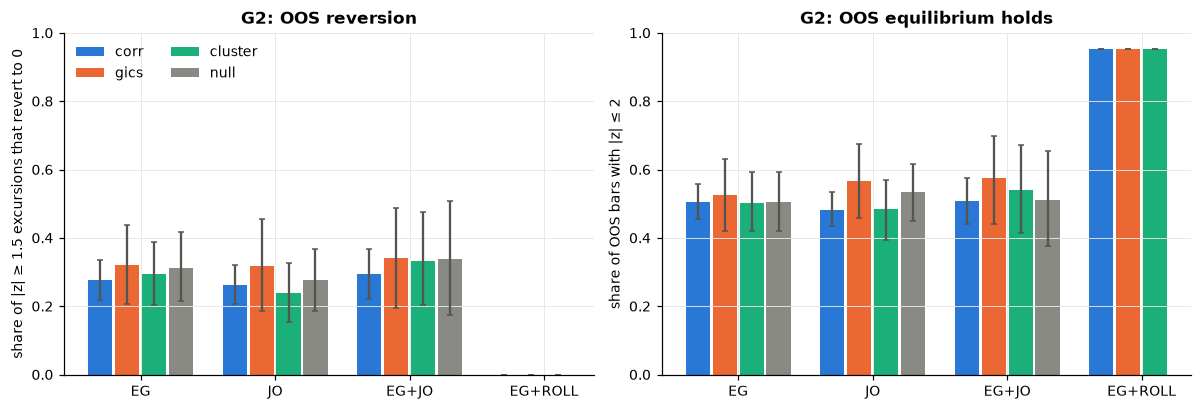

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=False)
for ax, m, lab in [(axes[0], "reversion_rate", "share of |z| ≥ 1.5 excursions that revert to 0"),
                   (axes[1], "band_hold", "share of OOS bars with |z| ≤ 2")]:
    w = 0.2
    for j, name in enumerate(["corr", "gics", "cluster", "null"]):
        vals, lo, hi = [], [], []
        for rule in RULES:
            d = oos_rows[(name, rule)]
            mu, l, h = mean_ci(d[m]) if len(d) else (np.nan,) * 3
            vals.append(mu); lo.append(mu - l if np.isfinite(mu) else 0); hi.append(h - mu if np.isfinite(mu) else 0)
        ax.bar(np.arange(len(RULES)) + (j - 1.5) * w, vals, w * 0.9, color=COL[name], label=name,
               yerr=[lo, hi], capsize=2, ecolor="#555550")
    ax.set_xticks(range(len(RULES)), list(RULES)); ax.set_ylim(0, 1); ax.set_ylabel(lab)
axes[0].legend(frameon=False, ncol=2); axes[0].set_title("G2: OOS reversion"); axes[1].set_title("G2: OOS equilibrium holds")
fig.tight_layout(); plt.show()

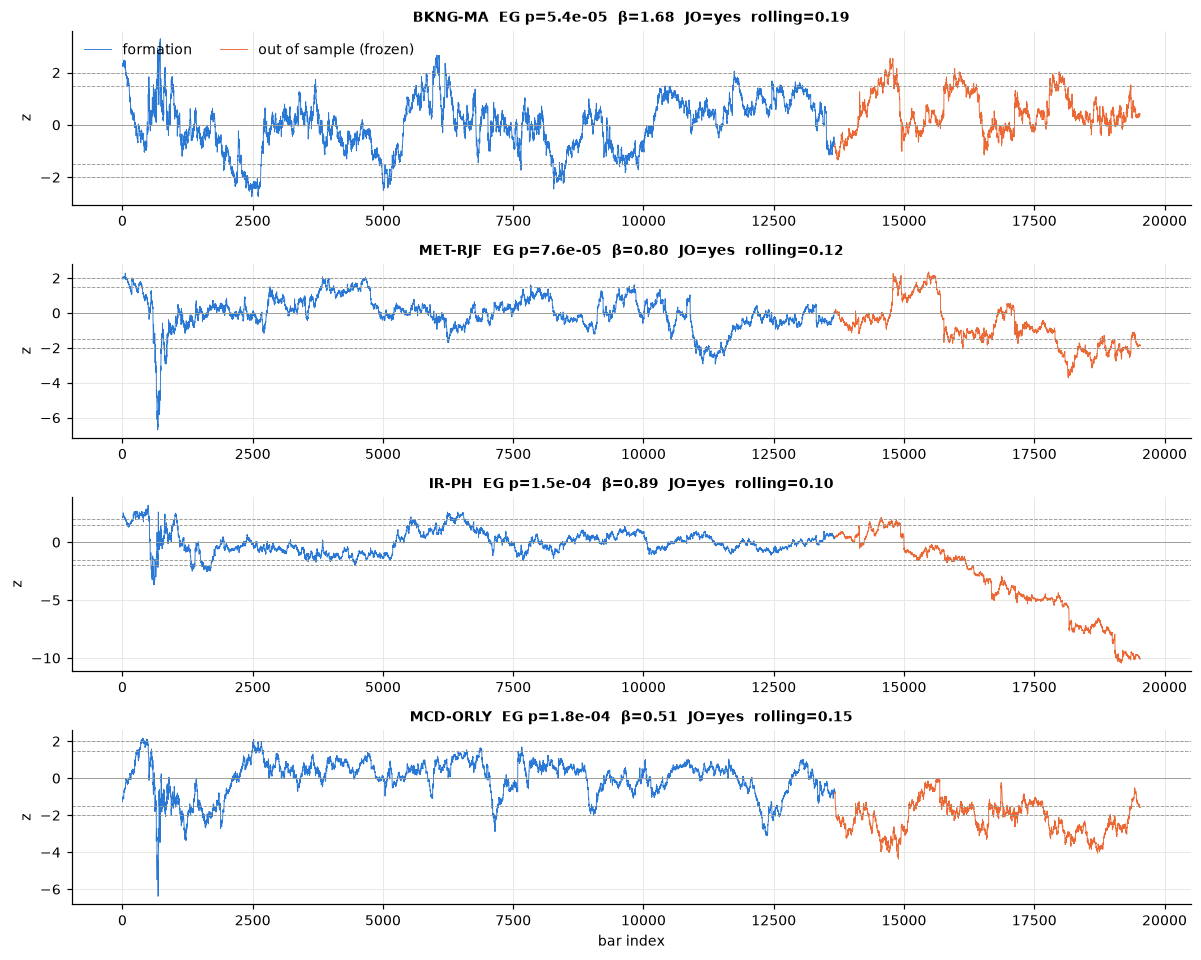

In [11]:
# The four thesis-selected pairs with the lowest EG p-value: formation and OOS z-score with frozen parameters
top = rows_of("corr").query("eg_selected").nsmallest(4, "eg_p")
if len(top):
    fig, axes = plt.subplots(len(top), 1, figsize=(11, 2.2 * len(top)), sharex=False)
    axes = np.atleast_1d(axes)
    for ax, (pair, r) in zip(axes, top.iterrows()):
        uf = train_log[r.dependent] - r.alpha - r.beta * train_log[r.independent]
        uo = test_log[r.dependent] - r.alpha - r.beta * test_log[r.independent]
        mu, sd = uf.mean(), uf.std()
        x = np.arange(len(uf) + len(uo))
        ax.plot(x[:len(uf)], (uf - mu) / sd, color=COL["corr"], lw=0.6, label="formation")
        ax.plot(x[len(uf):], (uo - mu) / sd, color="#eb6834", lw=0.6, label="out of sample (frozen)")
        for z in (-2, -1.5, 0, 1.5, 2):
            ax.axhline(z, color="#9a9a95", lw=0.6, ls="-" if z == 0 else "--")
        ax.set_title(f"{pair}  EG p={r.eg_p:.1e}  β={r.beta:.2f}  JO={'yes' if r.jo_selected else 'no'}  rolling={r.roll_pass_share:.2f}", fontsize=9)
        ax.set_ylabel("z")
    axes[0].legend(frameon=False, ncol=2, loc="upper left"); axes[-1].set_xlabel("bar index")
    fig.tight_layout(); plt.show()

## 7. Comparison with the thesis's 98 daily pairs, and summary

In [12]:
th = pd.read_csv(ROOT / "src" / "equity_trading" / "reference" / "thesis_cointegrated_pairs_daily.csv")
th_in = th[th.dependent.isin(TICKERS) & th.independent.isin(TICKERS)]
pairs_th = [tuple(sorted((a, b))) for a, b in zip(th_in.dependent, th_in.independent)]
in_corr = set(pairs_th) & set(cand["corr"])
sel_th = screen.reindex([f"{a}-{b}" for a, b in in_corr])
cmp = {"thesis_pairs": len(th), "both_legs_retained": len(th_in), "in_intraday_top10_candidates": len(in_corr),
       "selected_intraday_EG": int(sel_th.eg_selected.sum()) if len(sel_th) else 0}
print(cmp)

summary = {"study": "S03", "timeframe": TIMEFRAME, "synthetic": SYNTHETIC, "years": YEARS, "config": CFG,
           "formation": [str(train_prices.index.min()), str(train_prices.index.max())],
           "oos": [str(test_prices.index.min()), str(test_prices.index.max())],
           "assets_retained": len(TICKERS), "candidates": {k: len(v) for k, v in cand.items()},
           "primary_verdict": prim.verdict, "verdicts": gates.set_index(["set", "rule"])["verdict"].unstack().to_dict(),
           "thesis_98_comparison": cmp,
           "versions": {"package": __version__, "alpaca": ALPACA_VERSION, "pairs": PAIRS_VERSION}}
(OUT / "summary.json").write_text(json.dumps(summary, indent=2, default=str))
screen[screen.eg_selected | screen.jo_selected].to_csv(OUT / "selected_pairs_formation.csv", float_format="%.6g")
print(json.dumps({k: summary[k] for k in ["primary_verdict", "verdicts"]}, indent=2))

{'thesis_pairs': 98, 'both_legs_retained': 96, 'in_intraday_top10_candidates': 68, 'selected_intraday_EG': 4}
{
  "primary_verdict": "NO_EXCESS",
  "verdicts": {
    "EG": {
      "cluster": "NO_EXCESS",
      "corr": "NO_EXCESS",
      "gics": "NO_EXCESS"
    },
    "EG+JO": {
      "cluster": "NO_EXCESS",
      "corr": "SELECTS_BUT_NOT_PERSISTENT",
      "gics": "SELECTS_BUT_NOT_PERSISTENT"
    },
    "EG+ROLL": {
      "cluster": "SELECTS_BUT_NOT_PERSISTENT",
      "corr": "SELECTS_BUT_NOT_PERSISTENT",
      "gics": "SELECTS_BUT_NOT_PERSISTENT"
    },
    "JO": {
      "cluster": "NO_EXCESS",
      "corr": "NO_EXCESS",
      "gics": "NO_EXCESS"
    }
  }
}
